# Add annotations and final annots into sdata / Using cells / Slides for HistoST
# Always using table_cells

In [ ]:
import sys
from pathlib import Path
import scanpy as sc
import anndata as ad
import spatialdata as sd
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib.colors import to_rgba
from functools import partial
from matplotlib import colors

# Add the project root to sys.path so that 'src' can be imported
project_root = Path.cwd().parents[2]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.constants import get_full_path

$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


## 1. Get final labels

### 1.1. Get initial labels

In [2]:
def build_labels_table(adata_files, csv):
    
    combination_data = []
    
    if os.path.exists(csv):
        df_labels = pd.read_csv(csv)
    else:
        df_labels = pd.DataFrame(columns=['sample_id', 'tissue', 'label1', 'label2', 'label3', 'cell_count'])

    for file in adata_files:

        adata = ad.read_h5ad(file)
        file_name = os.path.basename(file)
        sample_id = file_name.replace('adata_annots_cells_', '').replace('.h5ad', '')
        tissue = sample_id.rsplit('_', 1)[0]
        print("Reading file: ", file_name)

        combination_counts = adata.obs.groupby(['label1', 'label2', 'label3'], observed=True).size().reset_index(name='cell_count')
        
        combination_counts['sample_id'] = sample_id
        combination_counts['tissue'] = tissue
        
        combination_counts = combination_counts[['sample_id', 'tissue', 'label1', 'label2', 'label3', 'cell_count']]
        combination_data.append(combination_counts)

    new_combination_df = pd.concat(combination_data, ignore_index=True)

    os.makedirs(os.path.dirname(csv), exist_ok=True)

    df_labels = pd.concat([df_labels, new_combination_df], ignore_index=True).drop_duplicates()
    df_labels.to_csv(csv, index=False)
    
    return df_labels

In [ ]:
adata_dir = get_full_path('STHELAR_HistoST', 'adata_annots_cells', as_str=True)
adata_files = [os.path.join(adata_dir, f) for f in os.listdir(adata_dir) if f.endswith('.h5ad')]
print(f"Number of adata files: {len(adata_files)}")
print(adata_files)

Number of adata files: 32
['/path/to/data_legacy/data_HE2CellType/CT_DS/adata_annots_cells/adata_annots_cells_kidney_s2.h5ad', '/path/to/data_legacy/data_HE2CellType/CT_DS/adata_annots_cells/adata_annots_cells_bone_marrow_s0.h5ad', '/path/to/data_legacy/data_HE2CellType/CT_DS/adata_annots_cells/adata_annots_cells_bone_marrow_s1.h5ad', '/path/to/data_legacy/data_HE2CellType/CT_DS/adata_annots_cells/adata_annots_cells_bone_s0.h5ad', '/path/to/data_legacy/data_HE2CellType/CT_DS/adata_annots_cells/adata_annots_cells_brain_s0.h5ad', '/path/to/data_legacy/data_HE2CellType/CT_DS/adata_annots_cells/adata_annots_cells_breast_s0.h5ad', '/path/to/data_legacy/data_HE2CellType/CT_DS/adata_annots_cells/adata_annots_cells_breast_s1.h5ad', '/path/to/data_legacy/data_HE2CellType/CT_DS/adata_annots_cells/adata_annots_cells_breast_s3.h5ad', '/path/to/data_legacy/data_HE2CellType/CT_DS/adata_annots_cells/adata_annots_cells_breast_s6.h5ad', '/path/to/data_legacy/data_HE2CellType/CT_DS/adata_annots_cells/ad

In [ ]:
df_labels = build_labels_table(adata_files, '/path/to/ALHENA-paper/data/annots/labels_table_cells.csv')

Reading file:  adata_annots_cells_kidney_s2.h5ad
Reading file:  adata_annots_cells_bone_marrow_s0.h5ad
Reading file:  adata_annots_cells_bone_marrow_s1.h5ad
Reading file:  adata_annots_cells_bone_s0.h5ad
Reading file:  adata_annots_cells_brain_s0.h5ad
Reading file:  adata_annots_cells_breast_s0.h5ad
Reading file:  adata_annots_cells_breast_s1.h5ad
Reading file:  adata_annots_cells_breast_s3.h5ad
Reading file:  adata_annots_cells_breast_s6.h5ad
Reading file:  adata_annots_cells_cervix_s0.h5ad
Reading file:  adata_annots_cells_colon_s1.h5ad
Reading file:  adata_annots_cells_colon_s2.h5ad
Reading file:  adata_annots_cells_heart_s0.h5ad
Reading file:  adata_annots_cells_kidney_s0.h5ad
Reading file:  adata_annots_cells_kidney_s1.h5ad
Reading file:  adata_annots_cells_liver_s0.h5ad
Reading file:  adata_annots_cells_liver_s1.h5ad
Reading file:  adata_annots_cells_lung_s1.h5ad
Reading file:  adata_annots_cells_lung_s3.h5ad
Reading file:  adata_annots_cells_lymph_node_s0.h5ad
Reading file:  ada

### 1.2. Transform into final labels

In [ ]:
df_labels = pd.read_csv('/path/to/ALHENA-paper/data/annots/labels_table_cells.csv')

In [6]:
df_labels

,sample_id,tissue,label1,label2,label3,cell_count
0,kidney_s2,kidney,B,B,normal_cell,26814
1,kidney_s2,kidney,Endothelial,Angiogenic_endothelial_cells,normal_cell,34368
2,kidney_s2,kidney,Endothelial,Endothelial,normal_cell,15624
3,kidney_s2,kidney,Epithelial,Epithelial_tumor_cells,cancer_cell,57049
4,kidney_s2,kidney,Fibroblast,CAF,normal_cell,62335
...,...,...,...,...,...,...
312,tonsil_s1,tonsil,Plasma,Plasma,normal_cell,86599
313,tonsil_s1,tonsil,Smooth_muscle,Smooth_muscle,normal_cell,3891
314,tonsil_s1,tonsil,T,T,normal_cell,118965
315,tonsil_s1,tonsil,T,T_CD8,normal_cell,72900


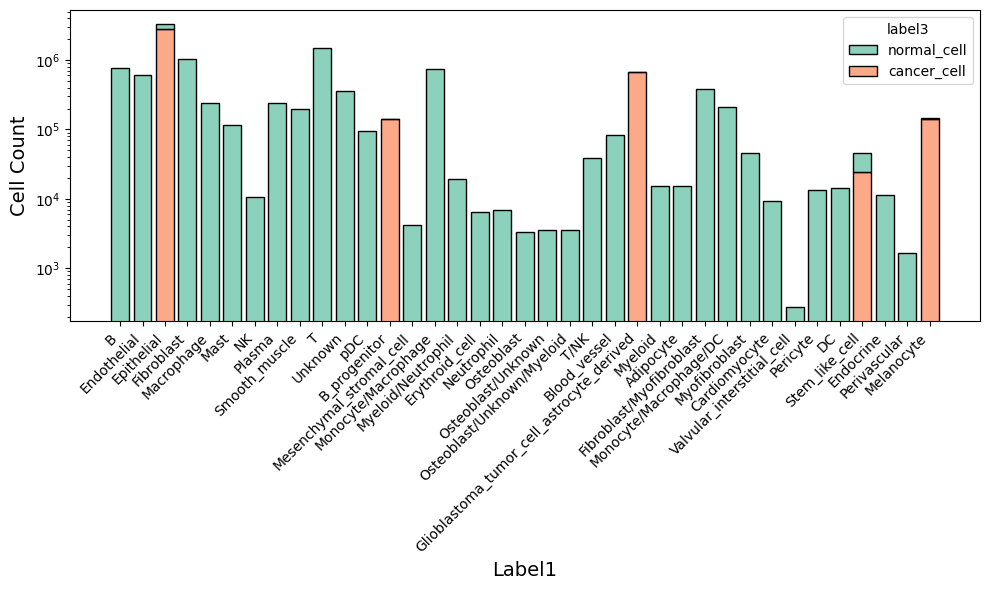

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df_labels, 
             x='label1', 
             hue='label3', 
             weights='cell_count',  # Use the cell count for actual counts
             multiple='stack', 
             shrink=0.8, 
             palette='Set2')

plt.yscale('log')
plt.xlabel('Label1', fontsize=14)
plt.ylabel('Cell Count', fontsize=14)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [8]:
group_labels = {

    # T/NK
    "T" : "T_NK",
    "T/NK" : "T_NK",
    "NK" : "T_NK",
    
    # B
    "B" : "B_Plasma",
    "B_blast" : "B_Plasma",
    "Proliferating_B_T" : "B_Plasma",
    "Plasma" : "B_Plasma",
    "B_progenitor" : "B_Plasma",
    
    # Monocyte/Macrophage/DC
    "Monocyte/Macrophage" : "Myeloid",
    "Monocyte/Macrophage/DC" : "Myeloid",
    "Macrophage" : "Myeloid",
    "DC" : "Myeloid",
    "Macrophage/DC" : "Myeloid",
    "Neutrophil" : "Myeloid",
    "Monocyte/Neutrophil" : "Myeloid",
    "Mast" : "Myeloid",
    "Myeloid" : "Myeloid",
    "Myeloid/Neutrophil" : "Myeloid",
    "pDC" : "Myeloid",  # pDC are grouped with the myeloid compartment here, although their lineage is debated

    # Fibroblast/Myofibroblast
    "Fibroblast" : "Fibroblast_Myofibroblast",
    "Fibroblast/Myofibroblast" : "Fibroblast_Myofibroblast",
    "Mesenchymal_stromal_cell" : "Fibroblast_Myofibroblast",
    "Myofibroblast" : "Fibroblast_Myofibroblast",

    # Blood_vessel
    "Perivascular" : "Blood_vessel",
    "Smooth_muscle" : "Blood_vessel",
    "Pericyte" : "Blood_vessel",
    "Myofibroblast/Pericyte" : "Blood_vessel",
    "Endothelial" : "Blood_vessel",
    "Blood_vessel" : "Blood_vessel",
    
    # Epithelial
    "Epithelial" : "Epithelial",
    "Keratinocyte" : "Epithelial",

    # Melanocyte
    "Melanocyte" : "Melanocyte",
    "Melanoma" : "Melanocyte",

    # Stem_like
    "Cancer_cell_with_stem_like_properties" : "Stem_like",
    "Proliferating_leukemic_blast" : "Stem_like",
    "Proliferating_blast" : "Stem_like",
    "Cancer_stem_like_cells" : "Stem_like",
    "Stem_like_cell" : "Stem_like",

    # Glioblastoma
    "Glioblastoma_tumor_cell_astrocyte_derived" : "Glioblastoma",

    # Specialized
    "Erythroid_cell" : "Specialized",
    "Osteoclast" : "Specialized",
    "Osteoblast" : "Specialized",
    "Cardiomyocyte" : "Specialized",
    "Adipocyte" : "Specialized",
    "Endocrine" : "Specialized",
    "Valvular_interstitial_cell" : "Specialized",

    # Unknown
    "Unknown" : "Unknown",
    "ToRemove" : "Unknown",
    "Osteoblast/Unknown" : "Unknown",
    "Osteoblast/Unknown/Myeloid" : "Unknown",
}

In [9]:
df_labels['final_label'] = df_labels['label1'].map(group_labels)

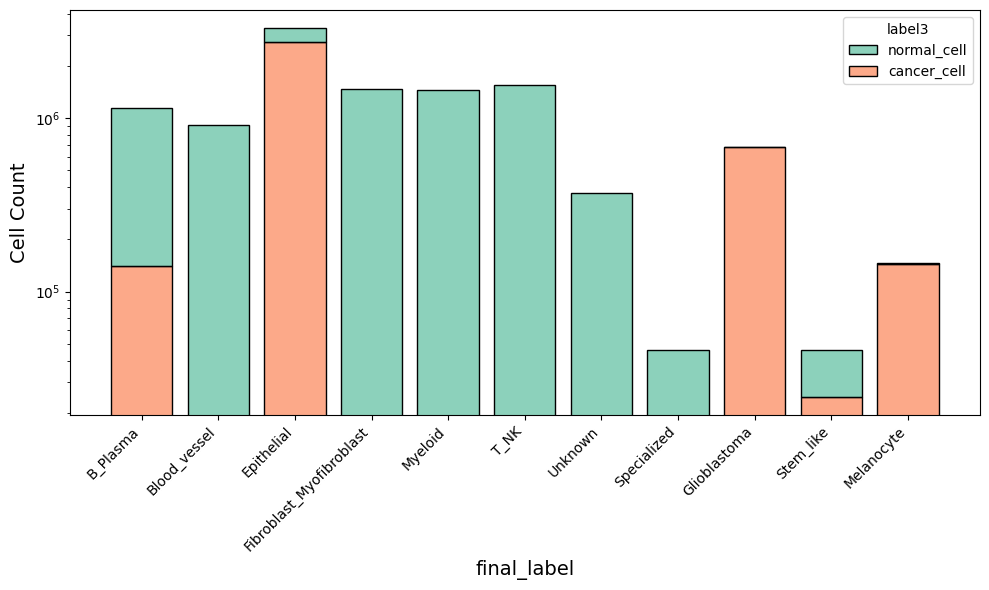

In [10]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df_labels,
             x='final_label', 
             hue='label3', 
             weights='cell_count',  # Use the cell count for actual counts
             multiple='stack', 
             shrink=0.8, 
             palette='Set2')

plt.yscale('log')
plt.xlabel('final_label', fontsize=14)
plt.ylabel('Cell Count', fontsize=14)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [11]:
df_labels['final_label'].unique()

array(['B_Plasma', 'Blood_vessel', 'Epithelial',
       'Fibroblast_Myofibroblast', 'Myeloid', 'T_NK', 'Unknown',
       'Specialized', 'Glioblastoma', 'Stem_like', 'Melanocyte'],
      dtype=object)

In [12]:
df_labels["final_label"].value_counts()

final_label
Myeloid                     63
Epithelial                  59
Blood_vessel                48
T_NK                        42
Fibroblast_Myofibroblast    40
B_Plasma                    32
Unknown                     14
Specialized                  7
Melanocyte                   7
Stem_like                    3
Glioblastoma                 2
Name: count, dtype: int64

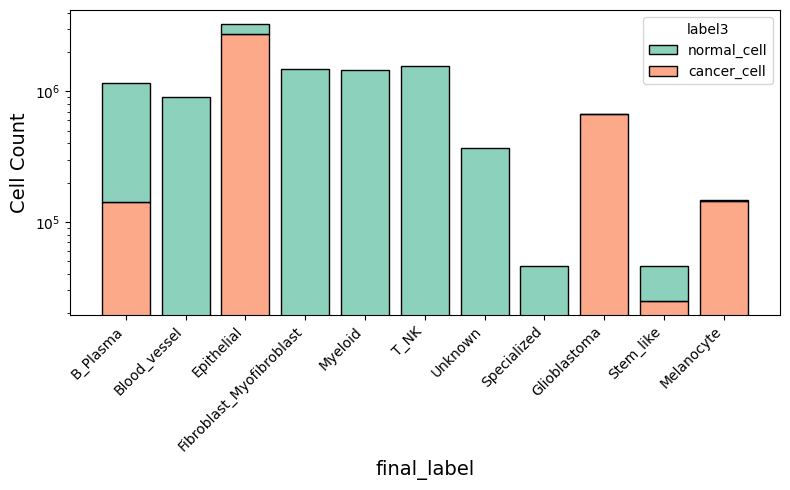

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_labels,
             x='final_label', 
             hue='label3', 
             weights='cell_count',  # Use the cell count for actual counts
             multiple='stack', 
             shrink=0.8, 
             palette='Set2')

plt.yscale('log')
plt.xlabel('final_label', fontsize=14)
plt.ylabel('Cell Count', fontsize=14)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [14]:
len(df_labels['final_label'].unique())

11

In [15]:
df_labels["final_label"].unique()

array(['B_Plasma', 'Blood_vessel', 'Epithelial',
       'Fibroblast_Myofibroblast', 'Myeloid', 'T_NK', 'Unknown',
       'Specialized', 'Glioblastoma', 'Stem_like', 'Melanocyte'],
      dtype=object)

In [16]:
# dict to put final label in each anndata

df_labels['combined_labels'] = df_labels[['label1', 'label2', 'label3']].astype(str).agg('_'.join, axis=1)
label_dict = df_labels.set_index('combined_labels')['final_label'].to_dict()
label_dict_unique = {k: v for k, v in label_dict.items()}
label_dict_unique

{'B_B_normal_cell': 'B_Plasma',
 'Endothelial_Angiogenic_endothelial_cells_normal_cell': 'Blood_vessel',
 'Endothelial_Endothelial_normal_cell': 'Blood_vessel',
 'Epithelial_Epithelial_tumor_cells_cancer_cell': 'Epithelial',
 'Fibroblast_CAF_normal_cell': 'Fibroblast_Myofibroblast',
 'Macrophage_TAM_normal_cell': 'Myeloid',
 'Mast_Mast_normal_cell': 'Myeloid',
 'NK_NK_normal_cell': 'T_NK',
 'Plasma_Plasma_normal_cell': 'B_Plasma',
 'Smooth_muscle_Smooth_muscle_normal_cell': 'Blood_vessel',
 'T_T_normal_cell': 'T_NK',
 'T_T_CD8_normal_cell': 'T_NK',
 'Unknown_Unknown_normal_cell': 'Unknown',
 'pDC_pDC_normal_cell': 'Myeloid',
 'B_progenitor_B_progenitor_cancer_cell': 'B_Plasma',
 'Fibroblast_Fibroblast_normal_cell': 'Fibroblast_Myofibroblast',
 'Mesenchymal_stromal_cell_MSC_normal_cell': 'Fibroblast_Myofibroblast',
 'Monocyte/Macrophage_Monocyte/Macrophage_normal_cell': 'Myeloid',
 'Myeloid/Neutrophil_Myeloid/Neutrophil_normal_cell': 'Myeloid',
 'Erythroid_cell_Erythroid_cell_normal_cel

In [17]:
label_dict_unique["less10_less10_less10"] = "Less10"

In [ ]:
# Save dict label_dict_unique in json file
with open("/path/to/ALHENA-paper/data/annots/label_dict_unique_cells.json", "w") as f:
    json.dump(label_dict_unique, f)

In [ ]:
# Save df_labels in csv file
df_labels.to_csv('/path/to/ALHENA-paper/data/annots/labels_table_cells.csv', index=False)

## 2. Analyze final dataset

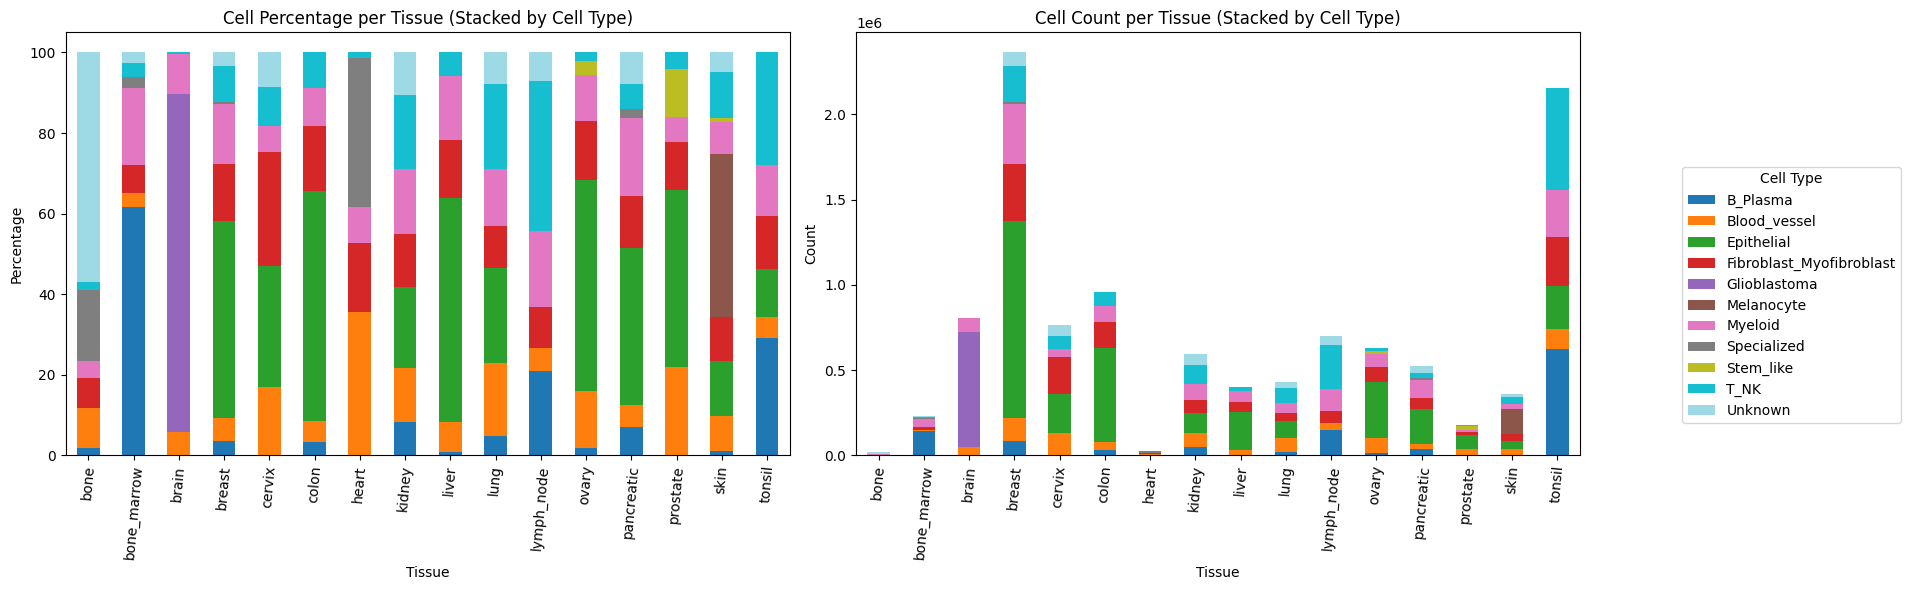

In [20]:
# Cell count per tissue, stacked by cell type

df_tissue_stacked = df_labels.pivot_table(index='tissue', columns='final_label', values='cell_count', aggfunc='sum', fill_value=0)
df_tissue_percentage = df_tissue_stacked.div(df_tissue_stacked.sum(axis=1), axis=0) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Stacked bar plot with percentages and log scale
df_tissue_percentage.plot(kind='bar', stacked=True, colormap='tab20', ax=ax1, legend=False)

ax1.set_title('Cell Percentage per Tissue (Stacked by Cell Type)')
ax1.set_xlabel('Tissue')
ax1.set_ylabel('Percentage')
ax1.set_xticklabels(df_tissue_percentage.index, rotation=85)

# Plot 2: Stacked bar plot with count
df_tissue_stacked.plot(kind='bar', stacked=True, colormap='tab20', ax=ax2, legend=False)

ax2.set_title('Cell Count per Tissue (Stacked by Cell Type)')
ax2.set_xlabel('Tissue')
ax2.set_ylabel('Count')
ax2.set_xticklabels(df_tissue_stacked.index, rotation=85)

# Create a single legend and place it outside the plot
handles, labels = ax1.get_legend_handles_labels()  # Get the legend info from one of the plots
fig.legend(handles, labels, title='Cell Type', bbox_to_anchor=(1.05, 0.5), loc='center left')

# Adjust layout for clarity
plt.tight_layout()  # Leave space on the right for the legend
plt.show()

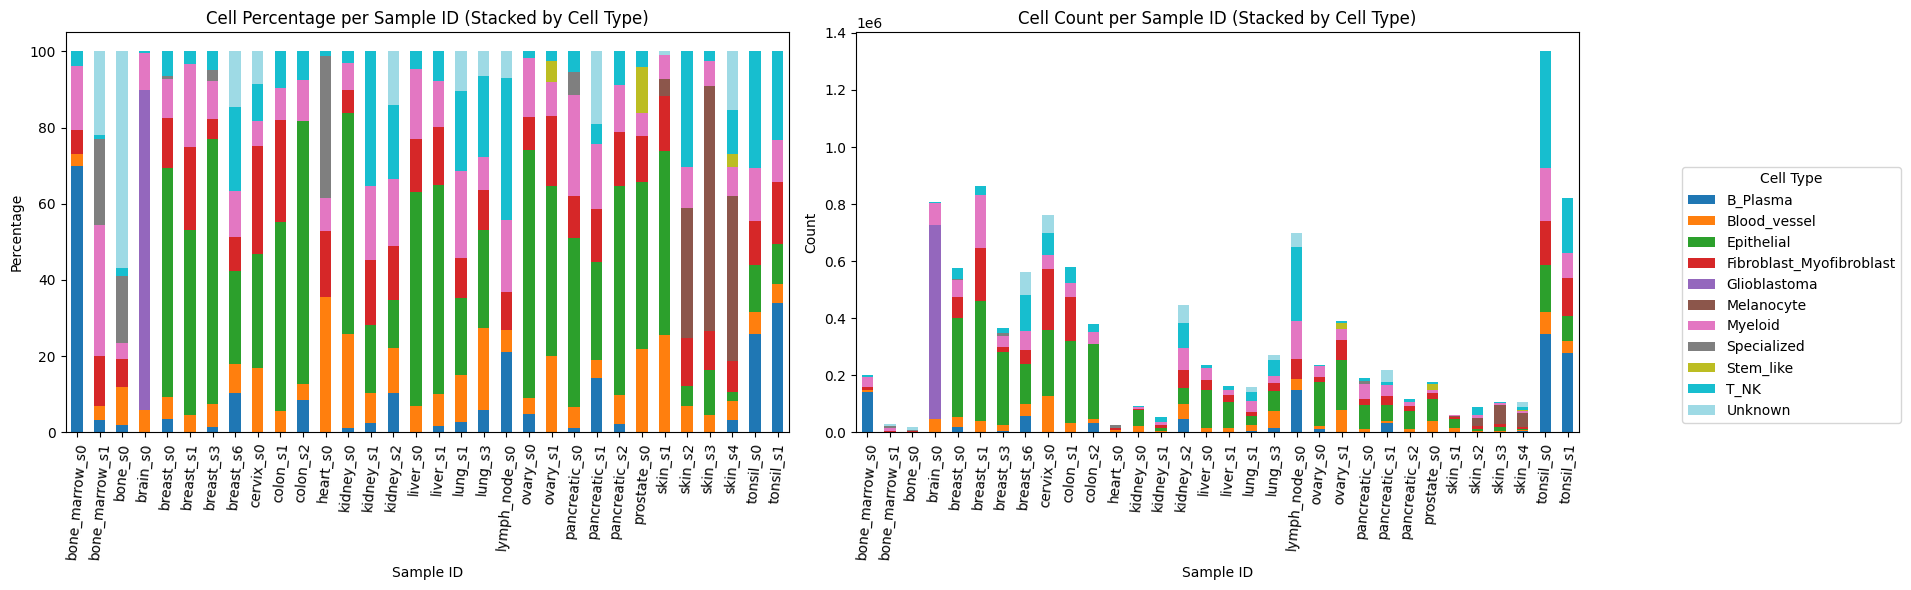

In [21]:
# Cell count per sample_id, stacked by cell type

df_sample_stacked = df_labels.pivot_table(index='sample_id', columns='final_label', values='cell_count', aggfunc='sum', fill_value=0)
df_sample_percentage = df_sample_stacked.div(df_sample_stacked.sum(axis=1), axis=0) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Stacked bar plot with percentages and log scale
df_sample_percentage.plot(kind='bar', stacked=True, colormap='tab20', ax=ax1, legend=False)

ax1.set_title('Cell Percentage per Sample ID (Stacked by Cell Type)')
ax1.set_xlabel('Sample ID')
ax1.set_ylabel('Percentage')
ax1.set_xticklabels(df_sample_percentage.index, rotation=85)

# Plot 2: Stacked bar plot with count
df_sample_stacked.plot(kind='bar', stacked=True, colormap='tab20', ax=ax2, legend=False)

ax2.set_title('Cell Count per Sample ID (Stacked by Cell Type)')
ax2.set_xlabel('Sample ID')
ax2.set_ylabel('Count')
ax2.set_xticklabels(df_sample_stacked.index, rotation=85)

# Create a single legend and place it outside the plot
handles, labels = ax1.get_legend_handles_labels()  # Get the legend info from one of the plots
fig.legend(handles, labels, title='Cell Type', bbox_to_anchor=(1.05, 0.5), loc='center left')

# Adjust layout for clarity
plt.tight_layout()  # Leave space on the right for the legend
plt.show()

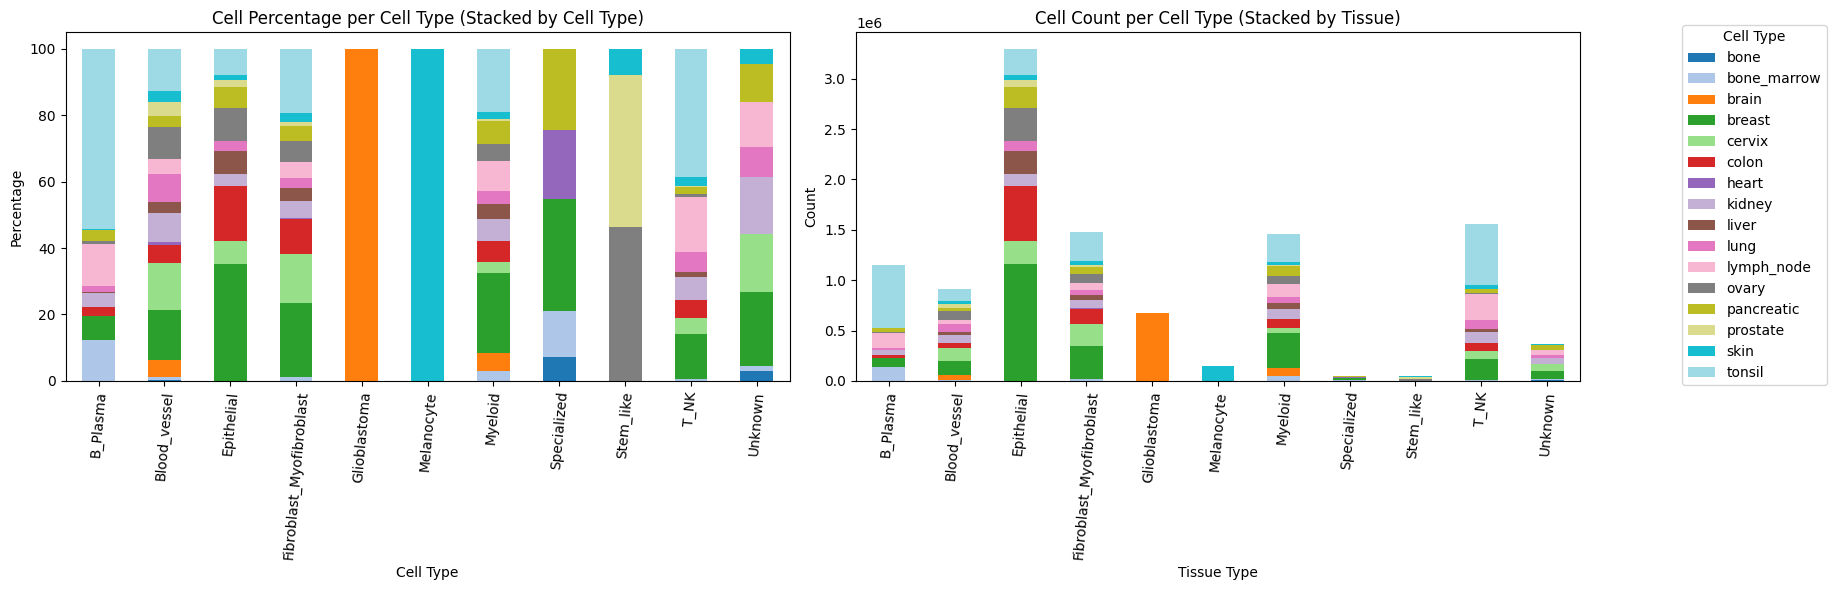

In [22]:
# Cell count per cell type, stacked by tissue

df_cell_type_stacked = df_labels.pivot_table(index='final_label', columns='tissue', values='cell_count', aggfunc='sum', fill_value=0)
df_cell_type_percentage = df_cell_type_stacked.div(df_cell_type_stacked.sum(axis=1), axis=0) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Stacked bar plot with percentages and log scale
df_cell_type_percentage.plot(kind='bar', stacked=True, colormap='tab20', ax=ax1, legend=False)

ax1.set_title('Cell Percentage per Cell Type (Stacked by Cell Type)')
ax1.set_xlabel('Cell Type')
ax1.set_ylabel('Percentage')
ax1.set_xticklabels(df_cell_type_percentage.index, rotation=85)

# Plot 2: Stacked bar plot with count
df_cell_type_stacked.plot(kind='bar', stacked=True, colormap='tab20', ax=ax2, legend=False)

ax2.set_title('Cell Count per Cell Type (Stacked by Tissue)')
ax2.set_xlabel('Tissue Type')
ax2.set_ylabel('Count')
ax2.set_xticklabels(df_cell_type_stacked.index, rotation=85)

# Create a single legend and place it outside the plot
handles, labels = ax1.get_legend_handles_labels()  # Get the legend info from one of the plots
fig.legend(handles, labels, title='Cell Type', bbox_to_anchor=(1.05, 0.65), loc='center left')

# Adjust layout for clarity
plt.tight_layout()  # Leave space on the right for the legend
plt.show()

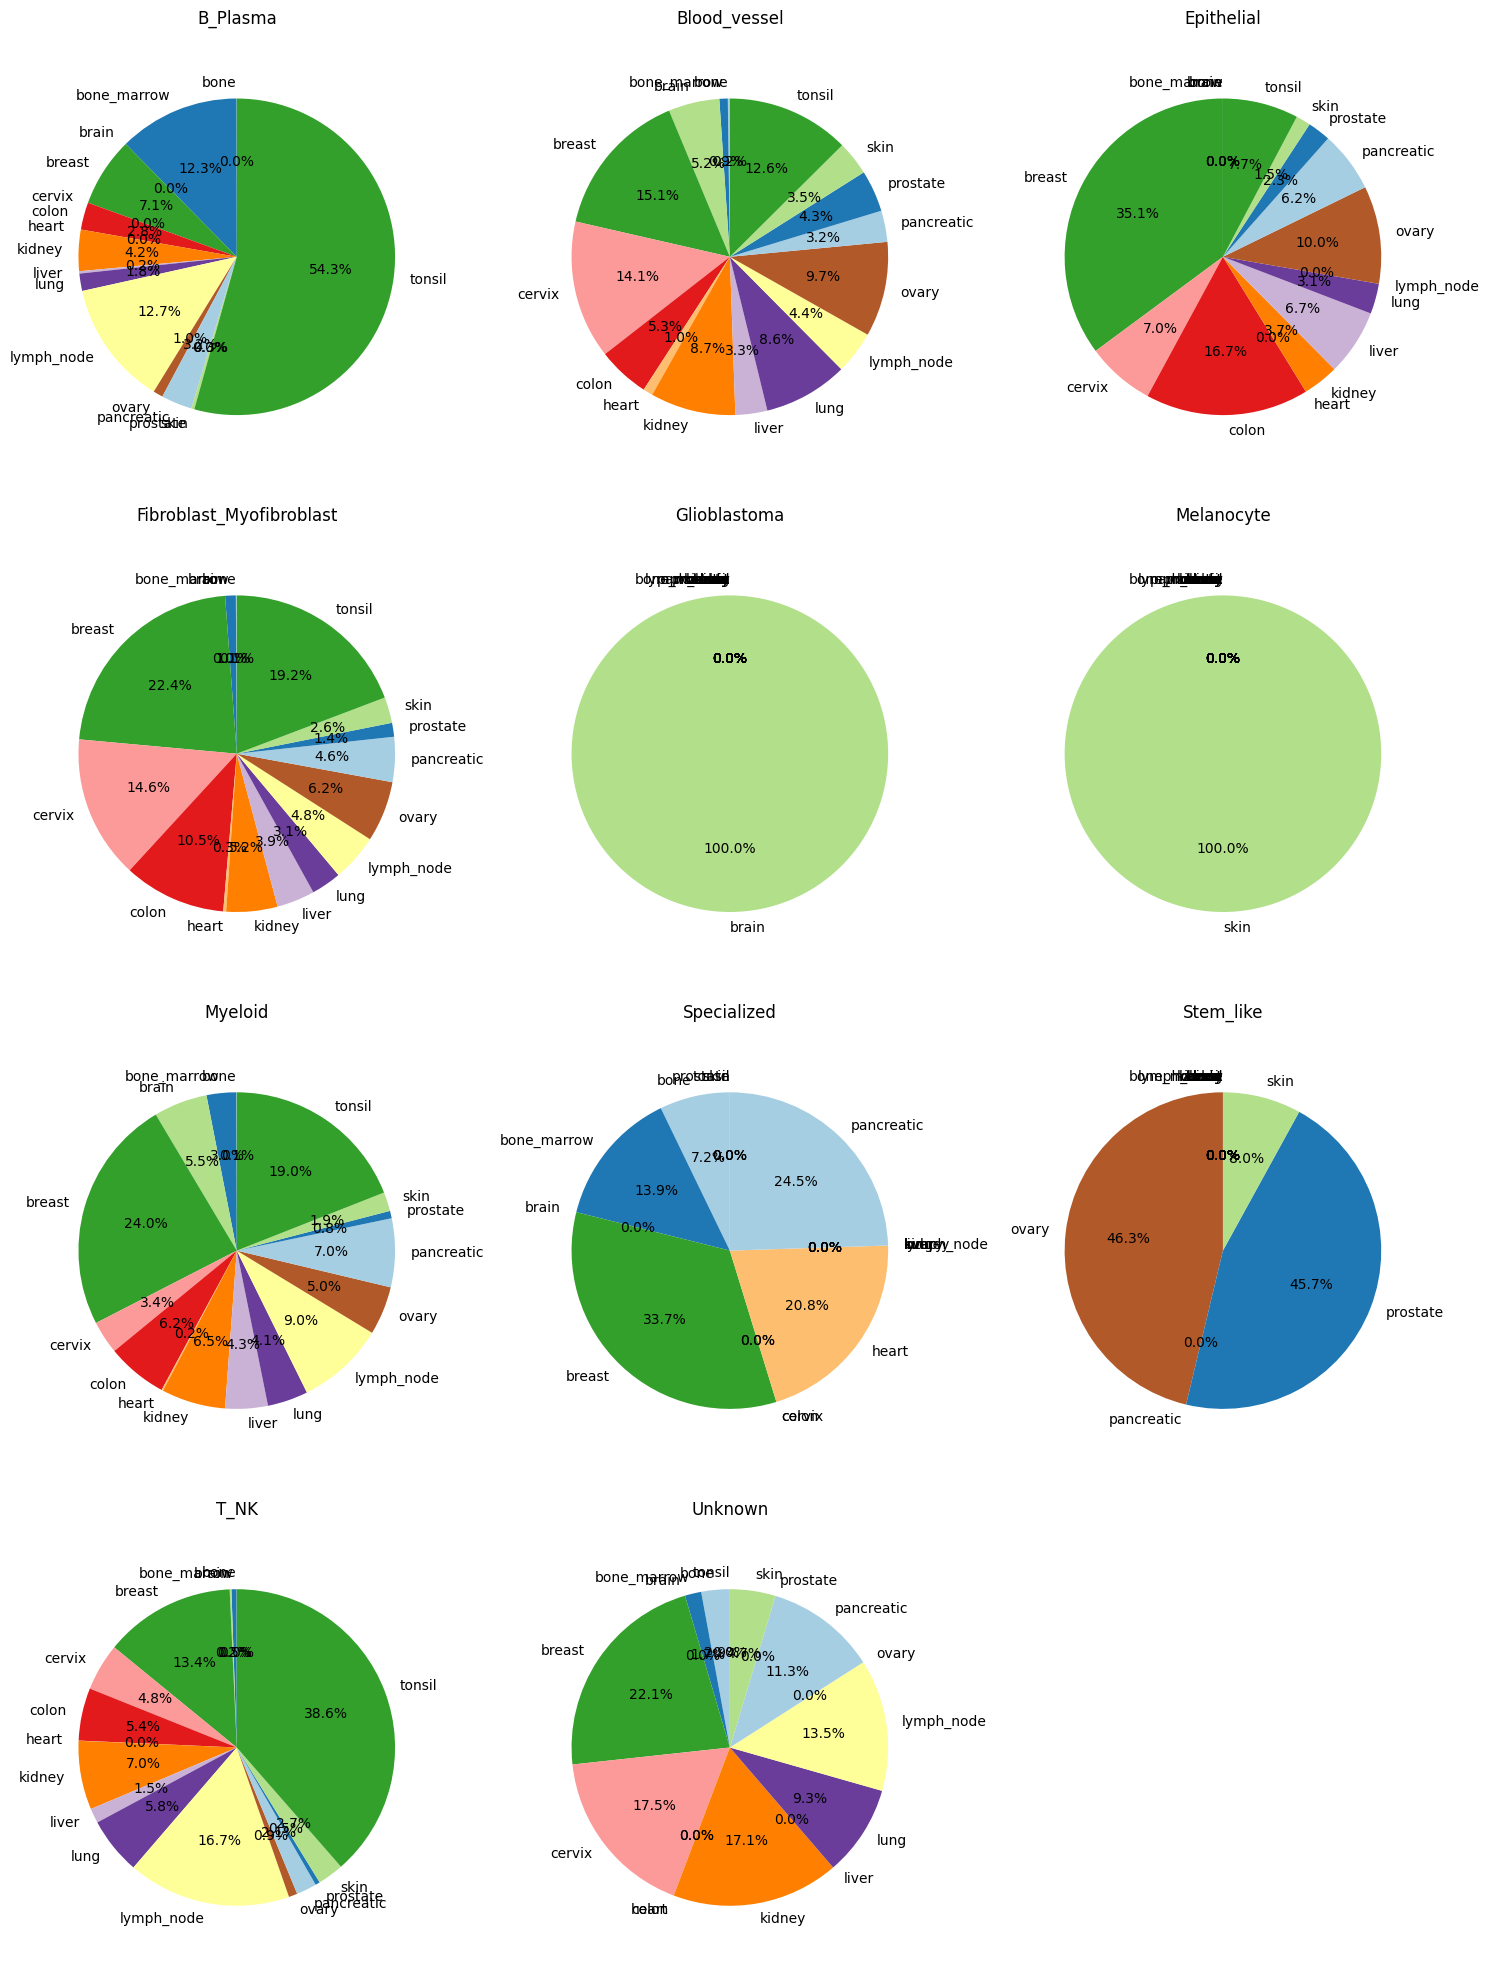

In [23]:
# Pie charts for tissue distribution in each cell type

df_grouped = df_labels.groupby(['final_label', 'tissue'])['cell_count'].sum().unstack(fill_value=0)

n_cell_types = len(df_grouped)
n_cols = 3 
n_rows = (n_cell_types // n_cols) + (n_cell_types % n_cols > 0)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 5))
axes = axes.flatten()

for i, (cell_type, row) in enumerate(df_grouped.iterrows()):
    ax = axes[i]
    ax.pie(row, labels=row.index, autopct='%1.1f%%', startangle=90, colors=plt.cm.Paired.colors)
    ax.set_title(f'{cell_type}')
    ax.axis('equal')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## 3. Apply final labels to each slide

In [ ]:
# Load the label_dict_unique from the JSON file
with open('/path/to/ALHENA-paper/data/annots/label_dict_unique_cells.json', 'r') as f:
    label_dict_unique = json.load(f)

In [25]:
# print unique values in label_dict_unique
print(set(label_dict_unique.values()))

{'Less10', 'Epithelial', 'Unknown', 'Blood_vessel', 'Myeloid', 'B_Plasma', 'Stem_like', 'T_NK', 'Glioblastoma', 'Melanocyte', 'Fibroblast_Myofibroblast', 'Specialized'}


In [26]:
# Color for final label in Napari

to_hex = partial(colors.to_hex, keep_alpha=True)

# Normalize the RGB values to the range [0, 1] by dividing by 255
napari_color = {
                "T_NK": to_hex(to_rgba([255/255, 15/255, 15/255])[:3]),                      # Red
                "B_Plasma": to_hex(to_rgba([255/255, 143/255, 15/255])[:3]),                 # Orange
                "Myeloid": to_hex(to_rgba([255/255, 211/255, 15/255])[:3]),                  # Yellow
                "Blood_vessel": to_hex(to_rgba([70/255, 128/255, 0/255])[:3]),               # Dark Green
                "Fibroblast_Myofibroblast": to_hex(to_rgba([156/255, 255/255, 36/255])[:3]), # Light Green
                "Epithelial": to_hex(to_rgba([57/255, 208/255, 133/255])[:3]),               # Blue Green
                "Specialized": to_hex(to_rgba([69/255, 237/255, 255/255])[:3]),              # Turquoise
                "Melanocyte": to_hex(to_rgba([22/255, 169/255, 223/255])[:3]),               # Blue
                "Stem_like": to_hex(to_rgba([22/255, 69/255, 223/255])[:3]),                 # Dark Blue
                "Glioblastoma": to_hex(to_rgba([130/255, 55/255, 235/255])[:3]),             # Purple
                "Unknown": to_hex(to_rgba([0/255, 0/255, 0/255])[:3]),                       # Black
                "Less10": to_hex(to_rgba([143/255, 143/255, 143/255])[:3])                   # Grey
                }

In [ ]:
def apply_final_labels(slide_id):

    print(f"\n===== Processing slide {slide_id} =====")

    adata_annot_path = get_full_path('STHELAR_HistoST', 'adata_annots_cells', f'adata_annots_cells_{slide_id}.h5ad', as_str=True)
    sdata_final_path = get_full_path('STHELAR_HistoST', 'sdata_final', f'sdata_{slide_id}.zarr', as_str=True)

    print("* Reading adata_annot...")
    adata_annot = sc.read_h5ad(adata_annot_path)
    print("* Reading sdata_final...")
    sdata_final = sd.read_zarr(sdata_final_path, selection=('tables',))

    print("* Applying final labels...")
    adata_annot.obs['combined_labels'] = adata_annot.obs[['label1', 'label2', 'label3']].astype(str).agg('_'.join, axis=1)
    adata_annot.obs['final_label'] = adata_annot.obs['combined_labels'].map(label_dict_unique)
    a2s_final = dict(adata_annot.obs[['cell_id', 'final_label']].values)

    print("* Updating sdata_final...")

    sdata_final.tables['table_cells'].obs['final_label'] = sdata_final.tables['table_cells'].obs['cell_id'].map(a2s_final).fillna('Less10')

    sdata_final.tables['table_cells'].obs['label1'] = sdata_final.tables['table_cells'].obs['label1'].astype(str).fillna('Unknown')
    sdata_final.tables['table_cells'].obs['label2'] = sdata_final.tables['table_cells'].obs['label2'].astype(str).fillna('Unknown')
    sdata_final.tables['table_cells'].obs['label3'] = sdata_final.tables['table_cells'].obs['label3'].astype(str).fillna('Unknown')

    sdata_final.tables['table_cells'].obs['final_label'] = sdata_final.tables['table_cells'].obs['final_label'].replace('nan', 'Unknown')
    sdata_final.tables['table_cells'].obs['label1'] = sdata_final.tables['table_cells'].obs['label1'].replace('nan', 'Unknown')
    sdata_final.tables['table_cells'].obs['label2'] = sdata_final.tables['table_cells'].obs['label2'].replace('nan', 'Unknown')
    sdata_final.tables['table_cells'].obs['label3'] = sdata_final.tables['table_cells'].obs['label3'].replace('nan', 'Unknown')

    print("* Adding color for Napari viz for final labels...")
    sdata_final.tables['table_cells'].uns["final_label_colors"] = napari_color

    return sdata_final

In [28]:
# slide_ids = ['breast_s0', 'breast_s1', 'breast_s3', 'breast_s6', 'lung_s1', 'lung_s3', 'skin_s1', 'skin_s2', 'skin_s3', 'skin_s4', 'pancreatic_s0', 
#              'pancreatic_s1', 'pancreatic_s2', 'heart_s0', 'colon_s1', 'colon_s2', 'kidney_s0', 'kidney_s1', 'liver_s0', 'liver_s1', 'tonsil_s0',
#              'tonsil_s1', 'lymph_node_s0', 'ovary_s0', 'ovary_s1', 'brain_s0', 'bone_marrow_s0', 'bone_marrow_s1', 'bone_s0', 'prostate_s0', 'cervix_s0']
slide_ids = ["kidney_s2"]
len(slide_ids)

1

In [29]:
for slide_id in slide_ids:
    sdata_final = apply_final_labels(slide_id)
    print("* Saving...")
    sdata_final.delete_element_from_disk("table_cells")
    sdata_final.write_element("table_cells")


===== Processing slide kidney_s2 =====
* Reading adata_annot...
* Reading sdata_final...


$HOME/miniforge3/envs/process_slide/lib/python3.12/site-packages/spatialdata/_core/spatialdata.py:184: UserWarning: The table is annotating 'cell_boundaries', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


* Applying final labels...
* Updating sdata_final...
* Adding color for Napari viz for final labels...
* Saving...
